# Which 311 complaint was most common in 2024?
We interpret “overall most abundant” as the most frequent complaint type in the **full filtered 2024 dataset**, across all boroughs. We then compare that same type in January–February and June–July.

Only complaints with a ZIP code are included. These are counts of reports, not necessarily distinct problems or residents. Open complaints still count.


## 1. Run our command-line tool
This helper runs the existing script and reads its small CSV output. Each call scans the dataset, so a full run takes a few minutes. It does not load the full dataset into memory.


In [1]:
import csv
import io
import sys
import subprocess
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

def counts_for(start, end):
    command = [sys.executable, "borough_complaints.py", "-i", "data/311_2024.csv", "-s", start, "-e", end]
    result = subprocess.run(command, capture_output=True, text=True, check=True)
    return list(csv.DictReader(io.StringIO(result.stdout)))


## 2. Add the borough counts for each complaint type
The Counter key is now just the complaint type, so its borough counts are added together.


In [2]:
annual_rows = counts_for("2024-01-01", "2024-12-31")
annual_totals = Counter()
for row in annual_rows:
    annual_totals[row["complaint type"]] += int(row["count"])
top_type, top_count = annual_totals.most_common(1)[0]
assert sum(annual_totals.values()) == 3423953
print(f"Total complaints: {sum(annual_totals.values()):,}")
print(f"Most common type: {top_type} ({top_count:,})")
print("Five most common types:")
for name, count in annual_totals.most_common(5):
    print(f"  {name}: {count:,}")


Total complaints: 3,423,953
Most common type: Illegal Parking (505,546)
Five most common types:
  Illegal Parking: 505,546
  Noise - Residential: 379,255
  HEAT/HOT WATER: 264,715
  Blocked Driveway: 170,140
  Noise - Street/Sidewalk: 162,990


## 3. Count the same type in four months
Each range includes both endpoint days. February has 29 days in 2024.


In [3]:
periods = [
    ("January", "2024-01-01", "2024-01-31", 31),
    ("February", "2024-02-01", "2024-02-29", 29),
    ("June", "2024-06-01", "2024-06-30", 30),
    ("July", "2024-07-01", "2024-07-31", 31),
]
monthly = []
for month, start, end, days in periods:
    rows = counts_for(start, end)
    count = sum(int(row["count"]) for row in rows if row["complaint type"] == top_type)
    monthly.append({"month": month, "count": count, "days": days})
    print(f"{month}: {count:,}", flush=True)


January: 41,124


February: 38,792


June: 46,370


July: 39,867


## 4. Draw the comparison
The bars show counts, not closure times. The gap separates the two time periods; March–May are not plotted.


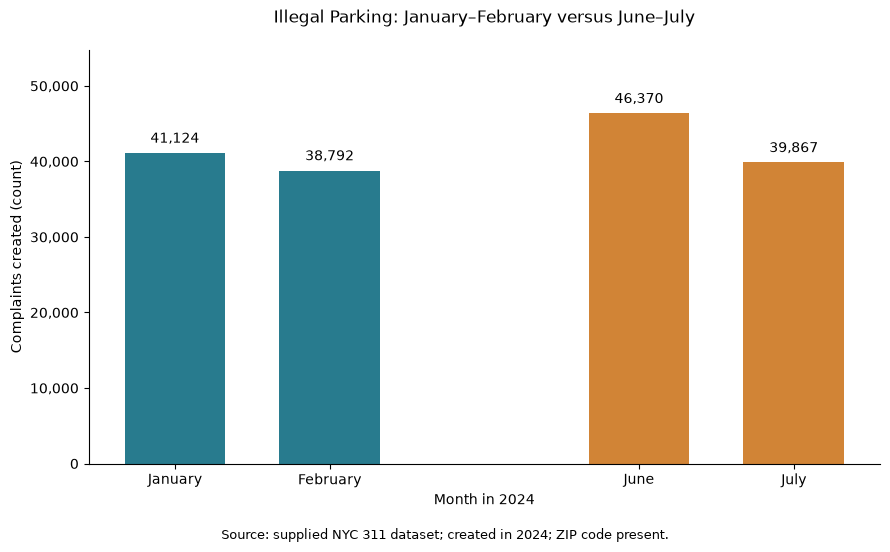

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
x = [0, 1, 3, 4]
values = [row["count"] for row in monthly]
bars = ax.bar(x, values, color=["#287b8e", "#287b8e", "#d18436", "#d18436"], width=0.65)
ax.set_xticks(x, [row["month"] for row in monthly])
ax.set_ylabel("Complaints created (count)")
ax.set_xlabel("Month in 2024")
ax.set_title(f"{top_type}: January–February versus June–July", pad=20)
ax.bar_label(bars, labels=[f"{value:,}" for value in values], padding=5)
ax.set_ylim(0, max(values) * 1.18)
ax.spines[["top", "right"]].set_visible(False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
fig.text(0.5, 0.01, "Source: supplied NYC 311 dataset; created in 2024; ZIP code present.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/complaint_comparison.png", dpi=160)
plt.show()


## 5. Compare totals and write the findings
The two periods have different lengths: 60 and 61 days. We report both raw totals and average reports per day. Neither establishes why the counts differ.


In [5]:
winter = sum(row["count"] for row in monthly[:2])
summer = sum(row["count"] for row in monthly[2:])
change = (summer / winter - 1) * 100
winter_daily = winter / 60
summer_daily = summer / 61
daily_change = (summer_daily / winter_daily - 1) * 100
month_lines = "\n".join(f'- {row["month"]}: {row["count"]:,} complaints' for row in monthly)
report = f"""# Complaint type analysis

## Method
We interpreted “overall most abundant” as the highest total complaint count across the full filtered 2024 dataset. We ran `borough_complaints.py` from Jupyter, then added each type's counts across boroughs. We selected complaints by creation date, including both range endpoints, and retained unclosed complaints. Only records with a ZIP code were included.

## Findings
**{top_type}** was the most common complaint type, with **{top_count:,}** reports out of **{sum(annual_totals.values()):,}** eligible complaints ({top_count/sum(annual_totals.values()):.1%}).

{month_lines}

January–February had **{winter:,}** reports; June–July had **{summer:,}**. The change from the first period to the second was **{summer-winter:+,} reports ({change:+.1f}%)**.

The periods contain 60 and 61 days respectively. Their daily averages were **{winter_daily:,.1f}** and **{summer_daily:,.1f}** reports, a **{daily_change:+.1f}%** change. This accounts for the unequal number of days.

![Complaint counts by month](figures/complaint_comparison.png)

## Interpretation and limitations
The chart describes the difference in reported complaint volume between these periods. It does not establish its cause or demonstrate a recurring seasonal pattern from one year alone. Counts may reflect reporting behavior as well as actual problems, and multiple reports can concern the same problem. Missing-ZIP complaints were excluded. These are complaint counts, not measurements of service quality or closure speed.

## Reproduce
Run `complaint_analysis.ipynb` from top to bottom with the filtered dataset in `data/311_2024.csv`. The notebook regenerates this report and the chart.
"""
Path("complaint_type_analysis.md").write_text(report)
print(report)


# Complaint type analysis

## Method
We interpreted “overall most abundant” as the highest total complaint count across the full filtered 2024 dataset. We ran `borough_complaints.py` from Jupyter, then added each type's counts across boroughs. We selected complaints by creation date, including both range endpoints, and retained unclosed complaints. Only records with a ZIP code were included.

## Findings
**Illegal Parking** was the most common complaint type, with **505,546** reports out of **3,423,953** eligible complaints (14.8%).

- January: 41,124 complaints
- February: 38,792 complaints
- June: 46,370 complaints
- July: 39,867 complaints

January–February had **79,916** reports; June–July had **86,237**. The change from the first period to the second was **+6,321 reports (+7.9%)**.

The periods contain 60 and 61 days respectively. Their daily averages were **1,331.9** and **1,413.7** reports, a **+6.1%** change. This accounts for the unequal number of days.

![Complaint counts by 